# ****PROBLEM UNDERSTANDING****

Notebook ini merumuskan masalah, tujuan, ruang lingkup, dan cara menilai keberhasilan proyek Optimasi Penentuan Interval Fuzzy Time Series Menggunakan Algoritma Genetika untuk Peramalan Harga Cabai Rawit Merah Berbasis Web.

<p align="center">
    <img src="../xLain_Lain/img/pu_0.png" alt="Problem Understanding" witdh="100" height="500">
</p>

---


### ****DAFTAR ISI****

0. Persiapan Lingkungan Kerja
1. Latar Belakang dan Bukti Awal dari Data
2. Perumusan Masalah dan Tujuan
3. Konteks Penggunaan Solusi (siapa yang memakai peramalan ini dan untuk apa)
4. Gambaran Metode: Fuzzy Time Series dan Algoritma Genetika
5. Ruang Lingkup, Asumsi, dan Batasan
6. Rancangan Evaluasi dan Kriteria Keberhasilan
7. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan Lingkungan Kerja****

#### ****0.1 Mengapa langkah ini penting?****

Kualitas sebuah penelitian data tidak hanya ditentukan oleh modelnya, tetapi juga oleh reproducibility, yaitu orang lain harus bisa menjalankan ulang pekerjaan ini dan mendapatkan hasil yang sama. Hal ini terasa lebih penting pada proyek kami karena Algoritma Genetika bersifat stokastik: hasilnya bisa berbeda setiap kali dijalankan, sehingga versi paket dan kondisi lingkungan perlu tercatat dengan jelas.

Informasi ini juga menentukan seberapa besar beban komputasi yang realistis. Kami berencana menjalankan optimasi GA berulang kali (sekitar 30 kali per konfigurasi), sehingga jumlah inti CPU dan memori akan memengaruhi keputusan desain eksperimen pada notebook-notebook berikutnya.

#### ****0.2 Memeriksa lingkungan kerja****

Sel berikut mencatat tiga hal:
1. Sistem operasi, versi Python, dan nama environment yang aktif.
2. Sumber daya komputasi (CPU, RAM, ruang disk).
3. Ketersediaan dan versi seluruh paket yang dibutuhkan.

In [3]:
import os
import sys
import shutil
import platform
from importlib import metadata

# 1. Sistem operasi, Python, dan environment
print("=" * 62)
print("1. SISTEM DAN PYTHON")
print("=" * 62)
print(f"Sistem operasi : {platform.system()} {platform.release()}")
print(f"Arsitektur : {platform.machine()}")
print(f"Versi Python : {platform.python_version()}")
print(f"Lokasi interpreter : {sys.executable}")
env_path = os.environ.get("VIRTUAL_ENV", sys.prefix)
print(f"Environment aktif : {os.path.basename(env_path)}")

# 2. Sumber daya komputasi
print()
print("=" * 62)
print("2. SUMBER DAYA KOMPUTASI")
print("=" * 62)
print(f"Jumlah inti logis : {os.cpu_count()}")
try:
    import psutil
    print(f"Jumlah inti fisik : {psutil.cpu_count(logical=False)}")
    ram = psutil.virtual_memory()
    print(f"RAM total : {ram.total / 1024**3:.1f} GB")
    print(f"RAM tersedia : {ram.available / 1024**3:.1f} GB")
except ImportError:
    print("RAM : psutil belum terpasang, bagian ini dilewati")

disk = shutil.disk_usage(os.getcwd())
print(f"Disk total : {disk.total / 1024**3:.1f} GB")
print(f"Disk tersedia : {disk.free / 1024**3:.1f} GB")

# 3. Ketersediaan dan versi paket
print()
print("=" * 62)
print("3. VERSI PAKET")
print("=" * 62)
paket = ["numpy", "pandas", "matplotlib", "scipy", "statsmodels",
         "scikit-learn", "streamlit", "openpyxl", "psutil", "ipykernel"]
belum = []
for nama in paket:
    try:
        print(f"{nama:<15}: {metadata.version(nama)}")
    except metadata.PackageNotFoundError:
        print(f"{nama:<15}: TIDAK TERPASANG")
        belum.append(nama)

print()
if belum:
    print("Paket yang perlu dipasang:", ", ".join(belum))
else:
    print("Semua paket yang dibutuhkan sudah terpasang.")

1. SISTEM DAN PYTHON
Sistem operasi : Windows 11
Arsitektur : AMD64
Versi Python : 3.13.11
Lokasi interpreter : d:\Data Proyek GitHub\KB_Final_Project\z_kb_fp\Scripts\python.exe
Environment aktif : z_kb_fp

2. SUMBER DAYA KOMPUTASI
Jumlah inti logis : 12
Jumlah inti fisik : 6
RAM total : 7.8 GB
RAM tersedia : 0.8 GB
Disk total : 307.6 GB
Disk tersedia : 75.7 GB

3. VERSI PAKET
numpy          : 2.5.5
pandas         : 3.1.1
matplotlib     : 3.11.2
scipy          : 1.18.1
statsmodels    : 0.15.0
scikit-learn   : 1.9.1
streamlit      : 1.67.0
openpyxl       : 3.1.5
psutil         : 7.2.2
ipykernel      : 7.4.0

Semua paket yang dibutuhkan sudah terpasang.


>INTERPRETASI (Lingkungan kerja)
>
>Pekerjaan ini dijalankan pada Windows 11 (AMD64) dengan Python 3.13.11 di dalam virtual environment bernama z_kb_fp, sehingga paket proyek terisolasi dari instalasi Python lain. Versi Python dan paket dicatat agar pekerjaan dapat direproduksi, misalnya numpy 2.5.5, pandas 3.1.1, dan matplotlib 3.11.2. Seluruh paket yang dibutuhkan sudah terpasang.
>
>Dari sisi sumber daya, komputer memiliki 12 inti logis (6 inti fisik) dan RAM total 7,8 GB. Namun RAM yang tersedia saat pengecekan hanya 1,5 GB karena sebagian besar sedang dipakai aplikasi lain. Ini menjadi batasan praktis utama. Data harga harian berukuran kecil (ribuan baris) dan Algoritma Genetika pada Fuzzy Time Series tidak membutuhkan memori besar, sehingga seluruh pekerjaan tetap realistis dilakukan secara lokal. Meski begitu, ketika eksperimen berulang dijalankan (sekitar 30 kali per konfigurasi).
>
>Keputusan untuk notebook berikutnya:
>1. Komputasi cukup dilakukan secara lokal tanpa GPU maupun layanan cloud.
>2. Kode Algoritma Genetika ditulis efisien dengan operasi vektor numpy.
>3. Seed acak dicatat di satu tempat (config.py) agar hasil dapat diulang.

### ****1. Latar Belakang dan Bukti Awal dari Data****

#### ****1.1 Mengapa langkah ini penting?****

Sebelum merancang model, kami perlu memastikan bahwa masalah yang diangkat benar-benar nyata dan terlihat pada data. Peramalan baru bermanfaat bila harga yang diramalkan memang bergejolak dan sulit ditebak dengan cara sederhana. Karena itu bagian ini menyajikan bukti awal dari data harga cabai rawit merah, sekaligus memperkenalkan sumber dan struktur data yang akan dipakai sepanjang proyek.

#### ****1.2 Sumber data dan struktur berkas****

Data berasal dari Pusat Informasi Harga Pangan Strategis (PIHPS) Nasional milik Bank Indonesia, yaitu harga harian cabai rawit merah di pasar tradisional Provinsi Jawa Timur, dari 1 Januari 2020 sampai 10 November 2026.

Berkas mentah berbentuk tabel lebar: setiap kolom adalah satu tanggal, tanggal tertulis dalam format hari/bulan/tahun, harga tersimpan sebagai teks dengan pemisah ribuan, dan data kosong ditandai dengan tanda hubung. Pencatatan hanya dilakukan pada hari kerja. Seluruh penyesuaian ini ditangani oleh satu fungsi pemuat data agar dapat dipakai ulang di semua notebook.

#### ****1.3 Bukti yang diperiksa****

Tiga sel berikut memeriksa hal-hal berikut:
1. Gambaran umum data: rentang waktu, jumlah data kosong, dan statistik ringkas harga.
2. Grafik harga harian dan sebaran perubahan harga dari hari ke hari.
3. Variasi harga per tahun dan lonjakan harian terbesar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from src.data_utils import muat_pihps_lebar

harga = muat_pihps_lebar(config.FILE_RAW, config.KOMODITAS)
valid = harga.dropna()

print("=" * 62)
print("Gambaran umum datanya")
print("=" * 62)
print(f"Komoditas : {config.KOMODITAS}")
print(f"Tanggal pertama : {harga.index.min().date()}")
print(f"Tanggal terakhir : {harga.index.max().date()}")
print(f"Jumlah hari tercatat : {len(harga)}")
print(f"Data kosong : {harga.isna().sum()} ({harga.isna().mean() * 100:.1f}%)")
print(f"Data valid : {len(valid)}")
print()
print(f"Rata-rata : Rp {valid.mean():,.0f}")
print(f"Median : Rp {valid.median():,.0f}")
print(f"Simpangan baku : Rp {valid.std():,.0f}")
print(f"Koefisien variasi : {valid.std() / valid.mean() * 100:.1f}%")
print(f"Harga terendah : Rp {valid.min():,.0f} ({valid.idxmin().date()})")
print(f"Harga tertinggi : Rp {valid.max():,.0f} ({valid.idxmax().date()})")
print(f"Rasio tertinggi/terendah : {valid.max() / valid.min():.1f} kali")

Gambaran umum datanya
Komoditas : Cabai Rawit Merah
Tanggal pertama : 2020-01-01
Tanggal terakhir : 2026-11-10
Jumlah hari tercatat : 1790
Data kosong : 44 (2.5%)
Data valid : 1746

Rata-rata : Rp 45,372
Median : Rp 40,025
Simpangan baku : Rp 21,960
Koefisien variasi : 48.4%
Harga terendah : Rp 10,250 (2020-08-21)
Harga tertinggi : Rp 110,800 (2021-03-18)
Rasio tertinggi/terendah : 10.8 kali


>INTERPRETASI (Gambaran umum data)
>
>Data mencakup 1.790 hari kerja dari 1 Januari 2020 sampai 10 November 2026, dengan 44 hari kosong (2,5%) sehingga tersisa 1.746 data valid. Jumlah ini cukup besar untuk membangun, melatih, dan menguji model dengan pembagian berurutan.
>
>Harga rata-rata Rp 45.372 per kg berada di atas mediannya (Rp 40.025), yang menandakan bahwa sesekali harga melonjak tinggi sehingga menarik rata-rata ke atas. Simpangan baku Rp 21.960 setara dengan koefisien variasi 48,4%, artinya harga biasanya menyimpang hampir setengah dari rata-ratanya sendiri. Rentang harga juga sangat lebar: terendah Rp 10.250 (21 Agustus 2020) dan tertinggi Rp 110.800 (18 Maret 2021), selisih 10,8 kali lipat.
>
>Temuan ini menunjukkan bahwa harga cabai rawit merah sangat bergejolak, sehingga peramalan memang relevan dan tidak sepele. Rentang yang lebar juga berdampak pada rancangan Fuzzy Time Series, karena semesta pembicaraan harus mencakup nilai dari sekitar Rp 10 ribu sampai di atas Rp 110 ribu.

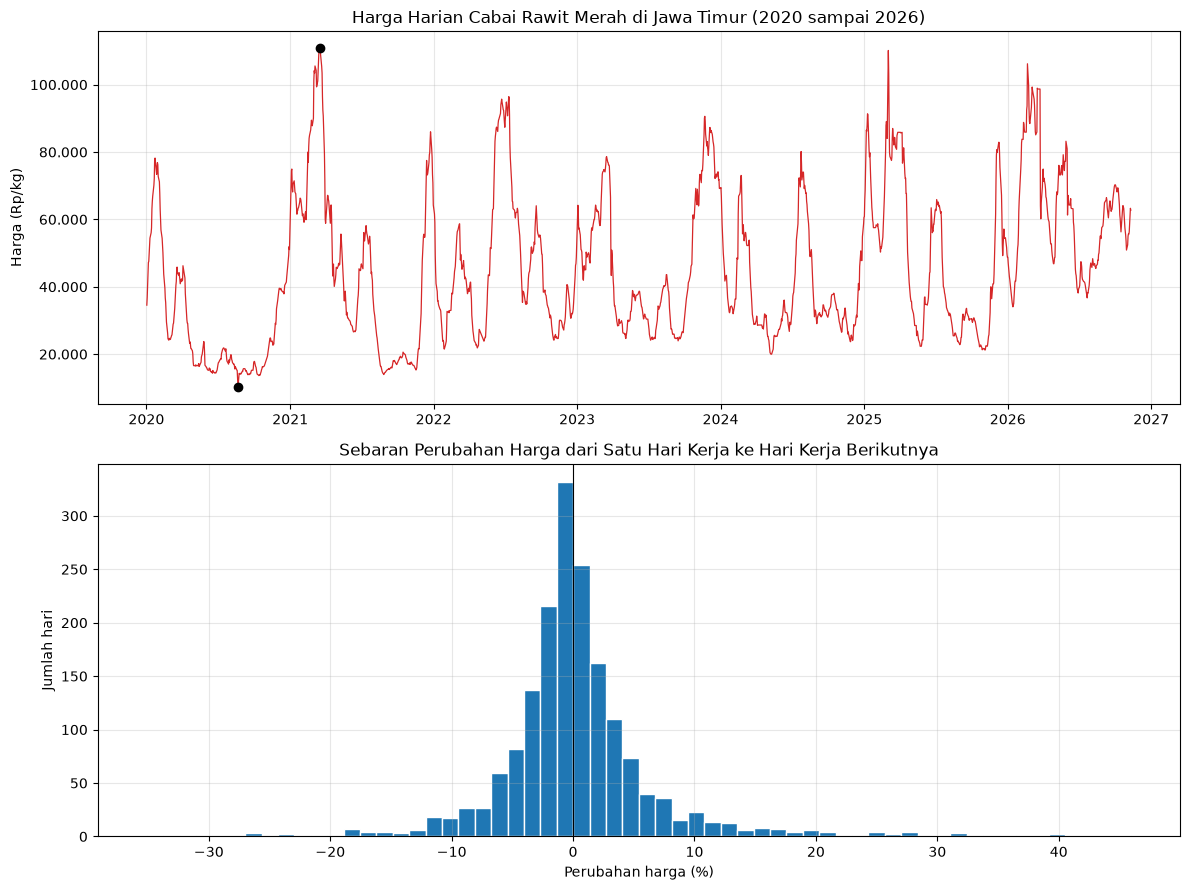

In [4]:
rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

fig, ax = plt.subplots(2, 1, figsize=(12, 9))

ax[0].plot(valid.index, valid.values, linewidth=0.9, color="tab:red")
ax[0].scatter([valid.idxmax(), valid.idxmin()], [valid.max(), valid.min()], color="black", zorder=3)
ax[0].set_title("Harga Harian Cabai Rawit Merah di Jawa Timur (2020 sampai 2026)")
ax[0].set_ylabel("Harga (Rp/kg)")
ax[0].yaxis.set_major_formatter(rupiah)
ax[0].grid(alpha=0.3)

perubahan = valid.pct_change().dropna() * 100
ax[1].hist(perubahan, bins=60, color="tab:blue", edgecolor="white")
ax[1].axvline(0, color="black", linewidth=0.8)
ax[1].set_title("Sebaran Perubahan Harga dari Satu Hari Kerja ke Hari Kerja Berikutnya")
ax[1].set_xlabel("Perubahan harga (%)")
ax[1].set_ylabel("Jumlah hari")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(config.DIR_IMG / "1_harga_harian_dan_sebaran_perubahan.png", dpi=150)
plt.show()

>INTERPRETASI (Grafik harga dan sebaran perubahan harian)
>
>Grafik atas memperlihatkan harga yang naik dan turun secara tajam dan berulang sepanjang tahun 2020 sampai 2026. Puncak harga terjadi berkali-kali, sering di sekitar awal tahun (misalnya 2021, 2025, dan 2026 yang mencapai kisaran Rp 100 ribu atau lebih), tetapi puncak juga muncul di pertengahan dan akhir tahun, sehingga polanya tidak seragam. Harga juga tidak bergerak di sekitar satu tingkat yang tetap: ia berayun antara kisaran Rp 20 ribu dan Rp 100 ribu dalam siklus beberapa bulan. Pola berulang tetapi tidak teratur seperti ini sulit ditebak dengan aturan sederhana. Penyebab lonjakan tidak diuji pada tahap ini.
>
>Grafik bawah menunjukkan bahwa perubahan harga dari satu hari kerja ke hari kerja berikutnya paling sering kecil, terkumpul di sekitar nol dan sebagian besar berada dalam kisaran beberapa persen. Namun kedua ekor sebarannya panjang: ada hari dengan kenaikan sampai sekitar 46% dan penurunan sampai sekitar 35%. Dengan kata lain, harga cenderung stabil dari hari ke hari, tetapi sesekali berubah drastis.
>
>Titik harga terendah (21 Agustus 2020) tampak terpisah dari kumpulan nilai di sekitarnya. Kami mencatatnya sebagai kandidat data tidak wajar untuk diperiksa pada tahap eksplorasi data di Notebook 3.

In [5]:
tahunan = valid.groupby(valid.index.year).agg(
    jumlah="count", rata2="mean", std="std", minimum="min", maksimum="max"
)
tahunan["koef_variasi_%"] = tahunan["std"] / tahunan["rata2"] * 100

print("=" * 62)
print("Statistik harga per tahun (Rp/kg)")
print("=" * 62)
print(tahunan.round(1).to_string())

perubahan = valid.pct_change().dropna() * 100
lonjakan = (perubahan.abs() > 10).sum()

print()
print("=" * 62)
print("Perubahan harian")
print("=" * 62)
print(f"Rata-rata perubahan : {perubahan.mean():.2f}%")
print(f"Simpangan baku perubahan : {perubahan.std():.2f}%")
print(f"Hari dengan perubahan > 10% : {lonjakan} dari {len(perubahan)} ({lonjakan / len(perubahan) * 100:.1f}%)")
print()
print("5 perubahan harian terbesar (nilai mutlak):")
terbesar = perubahan.reindex(perubahan.abs().sort_values(ascending=False).index).head(5)
for tgl, nilai in terbesar.items():
    print(f"  {tgl.date()}  {nilai:+.1f}%  (harga Rp {valid[tgl]:,.0f})")

Statistik harga per tahun (Rp/kg)
         jumlah    rata2      std  minimum  maksimum  koef_variasi_%
tanggal                                                             
2020        245  28241.6  16388.9  10250.0   78200.0            58.0
2021        248  46794.4  26957.3  13950.0  110800.0            57.6
2022        246  46354.5  20074.0  21500.0   96450.0            43.3
2023        260  47328.8  19575.3  23950.0   90600.0            41.4
2024        262  39009.5  14116.3  20000.0   80150.0            36.2
2025        261  49128.4  22354.7  21200.0  110150.0            45.5
2026        224  62250.4  17052.1  34050.0  106200.0            27.4

Perubahan harian
Rata-rata perubahan : 0.24%
Simpangan baku perubahan : 6.44%
Hari dengan perubahan > 10% : 157 dari 1745 (9.0%)

5 perubahan harian terbesar (nilai mutlak):
  2021-01-04  +45.9%  (harga Rp 74,500)
  2022-05-17  +39.5%  (harga Rp 34,950)
  2020-08-24  +39.5%  (harga Rp 14,300)
  2025-06-02  +36.4%  (harga Rp 33,000)
  2026-03-

>INTERPRETASI (Variasi per tahun dan lonjakan harian)
>
>Rata-rata harga tahunan bergerak dari Rp 28.242 (2020) ke kisaran Rp 46 ribu sampai Rp 49 ribu pada 2021 sampai 2023, turun menjadi Rp 39.010 pada 2024, lalu naik lagi menjadi Rp 49.128 (2025) dan Rp 62.250 (2026, data sampai 10 November). Artinya tingkat harga tidak tetap dari tahun ke tahun, dan data terbaru berada di level yang lebih tinggi daripada data awal.
>
>Koefisien variasi tertinggi ada pada 2020 dan 2021 (sekitar 58%), kemudian menurun hingga 27,4% pada 2026. Tahun 2026 memiliki harga rata-rata tertinggi tetapi variasi relatif terendah, yang berarti tingginya harga tidak selalu sejalan dengan makin liarnya fluktuasi. Karena data dipakai dengan pembagian berurutan, bagian akhir data yang menjadi data uji akan berada pada level harga yang berbeda dari data latih, dan hal ini harus kami perhatikan saat mengevaluasi model.
>
>Perubahan harian rata-rata hanya 0,24%, tetapi simpangan bakunya 6,44%, dan 157 dari 1.745 hari (9,0%) berubah lebih dari 10%. Ini berarti sekitar satu dari sebelas hari terjadi lonjakan atau penurunan yang besar. Lima perubahan terbesar berkisar dari kenaikan 45,9% (4 Januari 2021) sampai penurunan 35,1% (25 Maret 2026). Tiga dari lima kejadian itu jatuh pada hari Senin, dan dua melintasi hari kosong (4 Januari 2021 melewati 31 Desember dan 1 Januari, serta 17 Mei 2022 melewati 16 Mei), sehingga sebagian lonjakan mungkin mencerminkan jeda waktu antar-pencatatan dan bukan murni perubahan satu hari. Hal ini akan kami periksa di Notebook 3.

#### ****1.4 Ringkasan bukti awal****

Dari data yang diperiksa, ada empat temuan utama:
1. Data cukup besar, yaitu 1.746 data valid selama hampir tujuh tahun dengan hanya 2,5% hari kosong.
2. Harga sangat bergejolak, dengan koefisien variasi 48,4% dan selisih harga tertinggi terhadap terendah sebesar 10,8 kali lipat.
3. Pola naik turun berulang tetapi tidak teratur, dan tingkat harga berubah dari tahun ke tahun.
4. Harga cenderung stabil dari hari ke hari, tetapi sekitar 9% hari mengalami perubahan lebih dari 10%.

Temuan ini mendukung perlunya metode peramalan yang dapat menangani ketidakpastian dan perubahan tajam, dan inilah alasan kami memilih pendekatan Fuzzy Time Series.

### ****2. Perumusan Masalah dan Tujuan****

#### ****2.1 Mengapa langkah ini penting?****

Bukti awal pada bagian sebelumnya menunjukkan bahwa harga cabai rawit merah bergejolak. Sebelum membangun model, kami perlu menuliskan masalahnya dengan tegas agar setiap eksperimen berikutnya punya acuan yang jelas dan hasilnya dapat dinilai benar atau salah, bukan hanya terlihat bagus.

#### ****2.2 Perumusan masalah****

Berdasarkan latar belakang tersebut, masalah yang diangkat adalah sebagai berikut:
1. Bagaimana meramalkan harga harian cabai rawit merah di Jawa Timur dengan metode Fuzzy Time Series?
2. Bagaimana Algoritma Genetika dapat dipakai untuk mencari batas interval Fuzzy Time Series yang optimal?
3. Seberapa besar perbaikan akurasi yang diberikan Fuzzy Time Series dengan interval hasil optimasi dibandingkan interval sama panjang dan model pembanding lainnya?
4. Bagaimana model terbaik dapat dikemas menjadi sistem berbasis web yang dapat dipakai pengguna?

#### ****2.3 Tujuan****

Tujuan umum proyek ini adalah membangun, mengevaluasi, dan men-deploy model peramalan harga cabai rawit merah yang menggabungkan Fuzzy Time Series dan Algoritma Genetika.

Tujuan khususnya:
1. Mengimplementasikan Fuzzy Time Series dengan interval sama panjang sebagai model dasar.
2. Mengimplementasikan Algoritma Genetika untuk mengoptimasi batas interval.
3. Membandingkan model hasil optimasi dengan model dasar dan model pembanding, yaitu naive, moving average, ARIMA, dan regresi atau perceptron.
4. Men-deploy model terbaik dalam aplikasi web yang menampilkan interval, grafik prediksi, dan prediksi periode berikutnya.

#### ****2.4 Hipotesis kerja****

Hipotesis kami: pada data uji, Fuzzy Time Series dengan interval hasil optimasi Algoritma Genetika menghasilkan kesalahan peramalan (MAPE dan RMSE) yang lebih rendah daripada Fuzzy Time Series dengan interval sama panjang.

Hipotesis ini dapat terbukti maupun tidak terbukti. Kedua hasil sama-sama kami laporkan, karena yang dinilai adalah kejujuran dan ketelitian pengujian.

### ****3. Konteks Penggunaan Solusi****

#### ****3.1 Mengapa langkah ini penting?****

Model peramalan yang akurat belum tentu berguna bila tidak jelas siapa yang memakainya dan keputusan apa yang dibantu. Konteks penggunaan menentukan hal-hal yang praktis: seberapa jauh ke depan harga perlu diramalkan, seberapa besar kesalahan yang masih dapat diterima, dan bagaimana hasilnya sebaiknya ditampilkan di aplikasi web.

#### ****3.2 Calon pengguna dan kebutuhannya****

Pengguna potensial dari peramalan harga cabai rawit merah adalah:
1. Petani dan pedagang, yang perlu memperkirakan arah harga untuk menentukan waktu menjual atau menyimpan hasil panen dan stok.
2. Pelaku usaha kuliner dan pedagang eceran, yang perlu merencanakan pembelian bahan baku dan menentukan harga jual.
3. Rumah tangga, yang ingin mengetahui apakah harga cenderung naik atau turun dalam waktu dekat.
4. Pihak yang memantau harga pangan di tingkat daerah, yang membutuhkan gambaran awal sebelum terjadi lonjakan harga.

Proyek ini tidak melibatkan survei pengguna, sehingga daftar di atas merupakan gambaran kebutuhan yang masuk akal dan bukan temuan lapangan.

#### ****3.3 Keputusan yang dibantu****

Peramalan harga hari kerja berikutnya membantu keputusan jangka pendek, misalnya kapan membeli dalam jumlah besar atau kapan menunda pembelian. Sistem ini ditujukan sebagai alat bantu pertimbangan, bukan pengganti penilaian pengguna. Karena harga cabai dapat berubah tajam dalam satu hari (pada bagian 1 terlihat sekitar 9% hari berubah lebih dari 10%), hasil peramalan sebaiknya ditampilkan bersama gambaran tingkat kesalahan model agar pengguna tidak terlalu bergantung pada satu angka tunggal.

#### ****3.4 Konsekuensi bagi rancangan sistem****

Konteks ini membawa tiga konsekuensi:
1. Target peramalan adalah harga hari kerja berikutnya (satu langkah ke depan), sesuai frekuensi data.
2. Kesalahan relatif (MAPE) menjadi ukuran utama, karena pengguna lebih mudah memahami selisih dalam persen daripada dalam rupiah.
3. Aplikasi web menampilkan grafik harga aktual dan prediksi, nilai prediksi berikutnya, serta metrik kesalahan model.

### ****4. Gambaran Metode: Fuzzy Time Series dan Algoritma Genetika****

#### ****4.1 Mengapa langkah ini penting?****

Bagian ini menjelaskan gagasan kedua metode sebelum implementasi, agar seluruh anggota tim memiliki pemahaman yang sama dan pilihan metode dapat dipertanggungjawabkan. Rincian kode dibahas di notebook berikutnya.

#### ****4.2 Fuzzy Time Series (model Chen orde satu)****

Fuzzy Time Series mengubah deret angka menjadi deret himpunan fuzzy, kemudian mempelajari pola perpindahan antarhimpunan tersebut. Alur kerjanya:
1. Menentukan semesta pembicaraan, yaitu rentang nilai dari harga terendah sampai tertinggi pada data latih, ditambah sedikit margin.
2. Membagi semesta menjadi beberapa interval, lalu setiap interval mewakili satu himpunan fuzzy bernama A1, A2, sampai An (misalnya dari harga sangat rendah hingga sangat tinggi).
3. Fuzzifikasi, yaitu memetakan setiap harga ke himpunan fuzzy yang cocok.
4. Membentuk hubungan logika fuzzy (FLR), misalnya A3 diikuti A4, dari urutan himpunan pada data latih.
5. Mengelompokkan hubungan yang memiliki sisi kiri sama menjadi grup hubungan logika fuzzy (FLRG), misalnya A3 diikuti A2, A3, atau A4.
6. Meramalkan dengan melihat himpunan fuzzy pada hari ini, mengambil grupnya, lalu menghitung nilai peramalan (defuzzifikasi) sebagai rata-rata titik tengah interval himpunan tujuan. Bila hari ini tidak punya kelompok, nilai peramalannya adalah titik tengah interval himpunan itu sendiri.

Metode ini dipilih karena tidak mensyaratkan asumsi statistik yang ketat, mudah ditelusuri (setiap prediksi dapat dijelaskan lewat aturan), dan cocok dengan sifat data yang bergejolak dan tidak pasti.

#### ****4.3 Masalah pada penentuan interval****

Kualitas Fuzzy Time Series sangat bergantung pada cara semesta dibagi. Pada praktik umum, interval dibuat sama panjang atau ditentukan secara manual. Pembagian seperti itu tidak memperhatikan pola data: rentang harga yang jarang muncul mendapat interval sebesar rentang yang sering muncul. Mencari batas interval terbaik adalah masalah optimasi, dan inilah titik masuk Algoritma Genetika.

#### ****4.4 Algoritma Genetika untuk mengoptimasi batas interval****

Algoritma Genetika mencari solusi dengan meniru proses seleksi alam. Dalam proyek ini:
1. Kromosom adalah kumpulan titik batas interval yang selalu terurut.
2. Populasi awal berisi kumpulan kromosom acak, ditambah satu kromosom berisi pembagian sama panjang sebagai titik awal pembanding.
3. Fungsi kecocokan (fitness) mengukur kualitas suatu pembagian interval lewat tingkat kesalahan peramalan pada data latih, sehingga kesalahan kecil berarti kecocokan tinggi.
4. Seleksi memilih kromosom yang lebih baik untuk menjadi induk generasi berikutnya.
5. Persilangan (crossover) menggabungkan dua induk menjadi kromosom baru.
6. Mutasi menggeser sebagian titik batas dengan perubahan kecil agar pencarian tetap menjelajah.
7. Elitisme mempertahankan kromosom terbaik dari satu generasi ke generasi berikutnya.
8. Proses berhenti setelah jumlah generasi tertentu atau ketika kecocokan terbaik tidak lagi membaik.

#### ****4.5 Pengamanan terhadap overfitting****

Karena Algoritma Genetika dapat mencocokkan interval terlalu pas dengan data latih, kami memakai tiga bagian data berurutan secara waktu: data latih untuk menghitung kecocokan, data validasi untuk memilih konfigurasi, dan data uji untuk melaporkan hasil akhir yang tidak pernah dipakai selama optimasi.

Karena Algoritma Genetika bersifat acak, setiap konfigurasi dijalankan berulang kali dengan seed berbeda, dan hasilnya dilaporkan sebagai rata-rata beserta simpangan bakunya.

#### ****4.6 Model pembanding****

Untuk menilai manfaat optimasi, hasil dibandingkan dengan:
1. Naive, yaitu harga besok sama dengan harga hari ini.
2. Moving average.
3. ARIMA.
4. Regresi atau perceptron.
5. Fuzzy Time Series dengan interval sama panjang, sebagai pembanding utama.

### ****5. Ruang Lingkup, Asumsi, dan Batasan****

#### ****5.1 Mengapa langkah ini penting?****

Menuliskan ruang lingkup, asumsi, dan batasan sejak awal membuat kesimpulan proyek tidak melebar melampaui bukti yang dimiliki. Hal ini juga melindungi kami dari klaim berlebihan ketika hasil eksperimen nanti dibaca oleh orang lain.

#### ****5.2 Ruang lingkup****

Yang tercakup dalam proyek ini:
1. Satu komoditas, yaitu cabai rawit merah, di pasar tradisional Provinsi Jawa Timur.
2. Data harian hari kerja dari 1 Januari 2020 sampai 10 November 2026.
3. Peramalan univariat, yaitu hanya memakai riwayat harga itu sendiri.
4. Peramalan satu langkah ke depan, yaitu harga hari kerja berikutnya.
5. Fuzzy Time Series model Chen orde satu dengan batas interval yang dioptimasi Algoritma Genetika.
6. Aplikasi web sebagai bentuk penerapan model.

Yang tidak tercakup:
1. Faktor luar seperti cuaca, musim tanam, hari raya, dan kebijakan pemerintah.
2. Komoditas lain dan data tingkat kabupaten atau kota.
3. Peramalan beberapa langkah ke depan.
4. Penerapan pada perangkat IoT dan sistem berskala produksi.

#### ****5.3 Asumsi****

1. Data PIHPS dianggap cukup akurat dan mewakili harga pasar tradisional di Jawa Timur.
2. Pola harga masa lalu masih memberi informasi yang berguna untuk meramalkan harga jangka pendek.
3. Hari kosong pada data merupakan hari libur atau hari tanpa pencatatan. Hari tersebut dihapus dan tidak diisi, sehingga dua pencatatan yang mengapitnya dianggap berurutan (keputusan dari Notebook 3).
4. Pembagian data berurutan waktu mencerminkan situasi nyata, yaitu model hanya mengetahui masa lalu saat meramalkan masa depan.

#### ****5.4 Batasan****

1. Model tidak melihat penyebab lonjakan harga, sehingga tidak dapat mengantisipasi lonjakan yang dipicu faktor luar.
2. Fuzzy Time Series hanya mengenal rentang harga yang ada pada data latih. Harga di luar rentang itu dipetakan ke himpunan fuzzy terdekat dan peramalannya tidak dapat melampaui batas tersebut.
3. Tingkat harga berubah dari tahun ke tahun (bagian 1), sehingga data uji yang berada di periode terakhir dapat memiliki tingkat harga berbeda dari data latih.
4. Data uji hanya mencakup sekitar satu tahun terakhir, sehingga kesimpulan akurasi hanya berlaku untuk periode itu.
5. Algoritma Genetika bersifat acak, sehingga hasil satu kali jalan tidak dapat dijadikan kesimpulan.
6. Data hanya mencakup hari kerja yang memiliki catatan harga, sehingga hari berikutnya berarti pencatatan berikutnya, yaitu hari kerja berikutnya yang memiliki data.

### ****6. Rancangan Evaluasi dan Kriteria Keberhasilan****

#### ****6.1 Mengapa langkah ini penting?****

Kriteria keberhasilan perlu ditetapkan sebelum eksperimen dijalankan. Bila ditetapkan sesudah melihat hasil, ukuran keberhasilan mudah disesuaikan dengan hasil yang kebetulan bagus, dan penilaian menjadi tidak jujur.

#### ****6.2 Pembagian data****

Data dibagi berurutan menurut waktu, tidak diacak, dengan perbandingan 70% data latih, 15% data validasi, dan 15% data uji. Hasil pembagian pada Notebook 3 dari 1.745 data bersih: 1.221 hari latih (2 Januari 2020 sampai 6 November 2024), 261 hari validasi (7 November 2024 sampai 6 November 2025), dan 263 hari uji (7 November 2025 sampai 10 November 2026).

#### ****6.3 Metrik kesalahan****

1. MAPE (Mean Absolute Percentage Error), yaitu rata-rata selisih mutlak antara harga aktual dan prediksi dibagi harga aktual, dinyatakan dalam persen. Ini ukuran utama karena mudah dipahami pengguna.
2. RMSE (Root Mean Squared Error), yaitu akar dari rata-rata kuadrat selisih antara harga aktual dan prediksi, dalam rupiah. RMSE lebih menghukum kesalahan besar.
3. MAE (Mean Absolute Error), yaitu rata-rata selisih mutlak dalam rupiah.

#### ****6.4 Protokol pengujian****

1. Semua model memakai skema yang sama, yaitu meramalkan harga hari kerja berikutnya dari data sampai hari ini.
2. Algoritma Genetika hanya memakai data latih untuk menghitung kecocokan.
3. Pemilihan konfigurasi (misalnya jumlah interval dan parameter Algoritma Genetika) memakai data validasi.
4. Data uji dipakai satu kali untuk pelaporan akhir.
5. Setiap konfigurasi Algoritma Genetika dijalankan 30 kali dengan seed berbeda, dan dilaporkan rata-rata, simpangan baku, nilai terbaik, dan nilai terburuknya.

#### ****6.5 Kriteria keberhasilan****

Karena perubahan harga dari hari ke hari umumnya kecil (rata-rata perubahan harian 0,24% pada bagian 1), model naive yang hanya mengulang harga kemarin diperkirakan menjadi pembanding yang kuat. Karena itu kriteria keberhasilan dirumuskan secara realistis:
1. Kriteria utama: Fuzzy Time Series dengan interval hasil optimasi memiliki MAPE data uji yang lebih rendah daripada Fuzzy Time Series dengan interval sama panjang pada jumlah interval yang sama (dibandingkan untuk 7, 10, 15, dan 20 interval).
2. Kriteria pendukung: hasil Algoritma Genetika cukup stabil antar-seed, ditunjukkan simpangan baku MAPE yang kecil dibandingkan selisihnya terhadap model dasar.
3. Posisi terhadap naive, moving average, ARIMA, dan regresi atau perceptron dilaporkan apa adanya, tanpa keharusan mengalahkan semuanya.
4. Sistem web berhasil berjalan dari awal sampai akhir dan menampilkan prediksi beserta metrik kesalahan.

### ****7. Ringkasan dan Langkah Berikutnya****

#### ****7.1 Ringkasan****

1. Masalah: harga cabai rawit merah di Jawa Timur sangat bergejolak (koefisien variasi 48,4%, selisih harga tertinggi dan terendah 10,8 kali lipat, dan sekitar 9% hari berubah lebih dari 10%).
2. Data: 1.790 hari kerja dari 1 Januari 2020 sampai 10 November 2026, dengan 1.746 data valid dan 44 hari kosong.
3. Tujuan: membangun dan mengevaluasi Fuzzy Time Series yang interval-nya dioptimasi Algoritma Genetika, lalu menerapkannya dalam aplikasi web.
4. Hipotesis: interval hasil optimasi menurunkan MAPE dan RMSE pada data uji dibandingkan interval sama panjang.
5. Evaluasi: pembagian data berurutan, metrik MAPE, RMSE, dan MAE, serta 30 kali pengulangan Algoritma Genetika per konfigurasi.

#### ****7.2 Langkah berikutnya****

1. Notebook 2 (pengumpulan data): mendokumentasikan sumber dan parameter pengunduhan, serta memeriksa keutuhan berkas mentah.
2. Notebook 3 (pra-pemrosesan dan eksplorasi): menangani data kosong dan data tidak wajar, menetapkan pembagian data, dan menyelidiki pola harga.
3. Notebook 4 sampai 8: model dasar, optimasi Algoritma Genetika, evaluasi, persiapan penerapan, dan analisis hasil serta keterbatasan.